# TP3.3 — Guided Exercise: Training a Conditional Diffusion Model (CDM)

**Introduction to Deep Generative Models **

For each practical exercise (TP), please work in groups of two or three. Then, create a **private GitHub repository** and add me (my GitHub is **arthur-75**) to your project. 

> This notebook transcribes the original PDF. Unfinished `xxx` placeholders and the original starter code have been retained. Use the previous DDPM exercises for the reused components.

This exercise extends the previous DDPM setup to include context-based training, allowing the model to generate samples conditioned on additional information, such as class labels or attributes. You will understand and implement Conditional Denoising Diffusion Models (CDDM).

## 1. Understanding Conditional Diffusion Models (CDM)

A Conditional Diffusion Model (CDM) extends DDPM by conditioning the model on additional information (e.g., class labels, textual descriptions, or other structured data). This enables controlled generation, where outputs are guided by specific attributes.

The denoising step in a conditional model is:

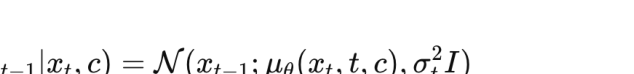

Where:
- `c` is contextual information (e.g., class labels).
- The model learns to remove noise conditioned on `c`.
- During training, a context-masking strategy is used, randomly ignoring context to ensure robustness.

## 2. Setup: Keeping the Same Components

For this exercise, we reuse the exact setup from the previous DDPM, ensuring consistency.

**Reused Components**

- Packages: Same PyTorch and utility imports.
- Network Hyperparameters: (e.g., feature dimensions, image size).
- Diffusion Hyperparameters: (e.g., number of timesteps, noise schedule).
- Training Hyperparameters: Learning rate, epochs, and batch size.
- DDPM Noise Schedule: Predefined beta schedule.
- Context U-Net Model: Supports conditional input.
- Denoising Function: `denoise_add_noise` remains the same.
- Dataset Handling: Uses `CustomDataset`.
- Perturbation Function: `perturb_input` remains unchanged.

*Use your setup from TP3.1 and TP3.2 before running the code below.*

## 3. Training a Conditional Diffusion Model

- Incorporating Context (`c`) into Training
- Randomly Masking Context (to prevent over-reliance)
- Updating the Loss Function (same as DDPM but conditioned on context)

**Implementation Steps**

1. Enable Training Mode.
2. Decay Learning Rate Linearly Over Epochs.
3. Loop Through Batches: extract images (`x`) and context (`c`), and convert them to the correct device (GPU/CPU).
4. Randomly Mask Out Context: apply Bernoulli masking to randomly nullify `c` with 90% probability (as described in the source).
5. Apply Noise to Input Images (`perturb_input`).
6. Train the U-Net to Predict Noise Given Context.
7. Compute Mean Squared Error Loss and Update Weights.
8. Save Model Periodically.

In [ ]:
# training with context code
# set into train mode
nn_model.train()

for ep in range(xxx):
    print(f'epoch {ep}')

    # linearly decay learning rate
    optim.param_groups[0]['lr'] = lrate*(1-ep/n_epoch)

    pbar = tqdm(xxx, mininterval=2 )
    for x, c in pbar:   # x: images  c: context
        optim.zero_grad()
        x = x.to(device)
        xxx = xxx.to(x)

        # randomly mask out c
        context_mask = torch.bernoulli(torch.zeros(c.shape[0]) + 0.9).to(device)
        c = c * context_mask.unsqueeze(-1)

        # perturb data
        noise = torch.randn_like(x)
        t = torch.randint(1, timesteps + 1, (x.shape[0],)).to(device)
        x_pert = xxx(xxx, xxx, xxx)

        # use network to recover noise
        pred_noise = xxxx(xxx, xxx / xxx, xxx=xxx)

        # loss is mean squared error between the predicted and true noise
        loss = F.mse_loss(xxx, xxx)
        loss.backward()
        optim.step()

    # save model periodically
    if ep%4==0 or ep == int(n_epoch-1):
        if not os.path.exists(save_dir):
            os.mkdir(save_dir)
        torch.save(nn_model.state_dict(), save_dir + f"context_model_{ep}.pth")
        print('saved model at ' + save_dir + f"context_model_{ep}.pth")

## 4. Sampling with Context

After training, we generate context-conditioned samples.

1. Load Pretrained Model and Set to Evaluation Mode.
2. Sample noise $x_T \sim \mathcal{N}(0,I)$.
3. Iteratively Remove Noise, Conditioned on Context.
4. Generate Samples and Visualize Them.

In [ ]:
# sample with context using standard algorithm
@torch.no_grad()
def sample_ddpm_context(xxx, xxx, save_rate=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    for i in range(timesteps, 0, -1):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        # sample some random noise to inject back in. For i = 1, don't add back in noise
        z = torch.randn_like(samples) if i > 1 else 0

        eps = nn_model(samples, t, c=context)    # predict noise e_(x_t,t, ctx)
        samples = denoise_add_noise(samples, i, eps, z)
        if i % save_rate==0 or i==timesteps or i<8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

## 5. Visualizing Context-Conditioned Samples

### Random Context Selection

In [ ]:
plt.clf()
ctx = F.one_hot(torch.randint(0, 5, (32,)), 5).to(device=device).float()
samples, intermediate = sample_ddpm_context(32, ctx)
animation_ddpm_context = plot_sample(intermediate, 32, 4, save_dir, "ani_run", None, save=False)
HTML(animation_ddpm_context.to_jshtml())

### Custom Context (User Defined)

In [ ]:
def show_images(imgs, nrow=2):
    _, axs = plt.subplots(nrow, imgs.shape[0] // nrow, figsize=(4,2 ))
    axs = axs.flatten()
    for img, ax in zip(imgs, axs):
        img = (img.permute(1, 2, 0).clone().clip(-1, 1).detach().cpu().numpy() +1) / 2
        ax.set_xticks([])
        ax.set_yticks([])
        ax.imshow(img)
    plt.show()

ctx = torch.tensor([
    [1,0,0,0,0],  # Hero
    [1,0,0,0,0],
    [0,0,0,0,1],  # Side-facing
    [0,0,0,0,1],
    [0,1,0,0,0],  # Non-hero
    [0,1,0,0,0],
    [0,0,1,0,0],  # Food
    [0,0,1,0,0],
]).float().to(device)
samples, _ = sample_ddpm_context(ctx.shape[0], ctx)
show_images(samples)

### Blending Multiple Contexts

In [ ]:
ctx = torch.tensor([
    [1,0,0,0,0],  # Human
    [1,0,0.6,0,0],
    [0,0,0.6,0.4,0],
    [1,0,0,0,1],
    [1,1,0,0,0],
    [1,0,0,1,0]
]).float().to(device)
samples, _ = sample_ddpm_context(ctx.shape[0], ctx)
show_images(samples)

## 4. DDIM with Context

Use the same `denoise_ddim` to plot.

*Section numbering retained from the original document.*

In [ ]:
# fast sampling algorithm with context
@torch.no_grad()
def sample_ddim_context(n_sample, context, n=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    step_size = timesteps // n
    for i in range(timesteps, 0, -step_size):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        eps = nn_model(samples, t, c=context)    # predict noise e_(x_t,t)
        samples = denoise_ddim(samples, i, i - step_size, eps)
        intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

# visualize samples
plt.clf()
ctx = F.one_hot(torch.randint(0, 5, (32,)), 5).to(device=device).float()
samples, intermediate = sample_ddim_context(32, ctx)
animation_ddpm_context = plot_sample(intermediate,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddpm_context.to_jshtml())

## Questions

1. Write the DDPM and DDIM equations and how do they work?
2. What is the difference between DDPM and DDIM? What is the advantage of each?

**Your answers:**

<!-- Write your answers here. -->